In [2]:
# Import required libraries

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import random

# Set random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Random seed:", SEED)

Libraries imported successfully!
PyTorch version: 2.15.0+cpu
Random seed: 42


In [3]:
# Set random seed

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Seed set successfully")

Seed set successfully


In [4]:
# Load CIFAR-10 dataset

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

100.0%


Training images: 50000
Test images: 10000


In [5]:
# Split training data into training and validation sets

from torch.utils.data import random_split

train_size = 45000
val_size = 5000

train_dataset, val_dataset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Train images: 45000
Validation images: 5000
Test images: 10000


In [6]:
# Create DataLoaders

from torch.utils.data import DataLoader

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")
print("Batch size:", batch_size)

DataLoaders created successfully!
Batch size: 128


In [7]:
# Create CNN model with three trainable layers

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.fc(x)
        return x


model = CNN()

print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)


In [8]:
# Test CNN output shape

images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([128, 3, 32, 32])
Output shape: torch.Size([128, 10])


In [9]:
# Calculate CNN trainable parameters

total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 60362


In [10]:
# Set loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.001")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


In [11]:
# Training function

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training function created successfully!")

Training function created successfully!


In [12]:
# Evaluation function

def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Evaluation function created successfully!")

Evaluation function created successfully!


In [13]:
# Train the CNN model

epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_acc:.2f}% "
        f"Validation Loss: {val_loss:.4f} "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Epoch [1/20] Train Loss: 1.5562 Train Accuracy: 44.66% Validation Loss: 1.3388 Validation Accuracy: 53.16%
Epoch [2/20] Train Loss: 1.2314 Train Accuracy: 56.86% Validation Loss: 1.1757 Validation Accuracy: 58.58%
Epoch [3/20] Train Loss: 1.1132 Train Accuracy: 61.21% Validation Loss: 1.0819 Validation Accuracy: 61.82%
Epoch [4/20] Train Loss: 1.0231 Train Accuracy: 64.67% Validation Loss: 1.0194 Validation Accuracy: 64.70%
Epoch [5/20] Train Loss: 0.9589 Train Accuracy: 66.96% Validation Loss: 0.9770 Validation Accuracy: 66.18%
Epoch [6/20] Train Loss: 0.9085 Train Accuracy: 68.69% Validation Loss: 0.9633 Validation Accuracy: 66.78%
Epoch [7/20] Train Loss: 0.8629 Train Accuracy: 70.44% Validation Loss: 0.9507 Validation Accuracy: 67.14%
Epoch [8/20] Train Loss: 0.8276 Train Accuracy: 71.59% Validation Loss: 0.9016 Validation Accuracy: 69.10%
Epoch [9/20] Train Loss: 0.7979 Train Accuracy: 72.74% Validation Loss: 0.9033 Validation Accuracy: 69.58%
Epoch [10/20] Train Loss: 0.7647 Trai

In [14]:
# Evaluate CNN on test dataset

test_loss, test_accuracy = evaluate(
    model, test_loader, criterion
)

print("CNN Test Loss:", round(test_loss, 4))
print("CNN Test Accuracy:", round(test_accuracy, 2), "%")

CNN Test Loss: 0.9142
CNN Test Accuracy: 70.4 %


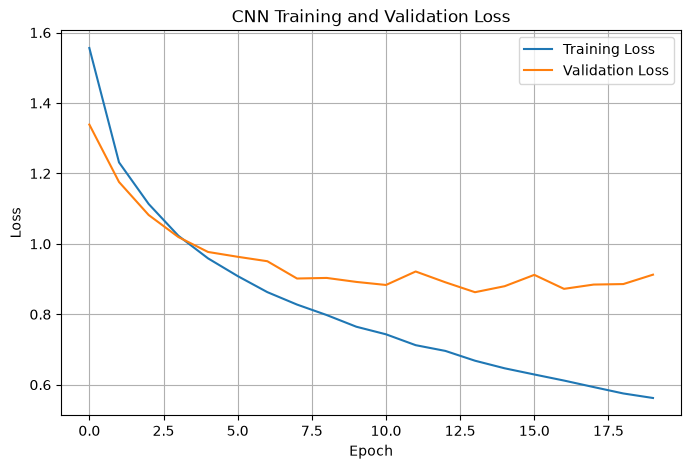

In [16]:
# Plot training and validation loss

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

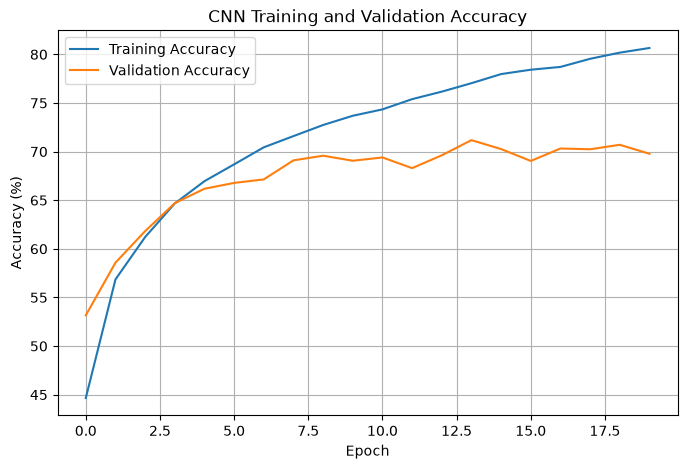

In [17]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()


In [18]:
# Compare MLP and CNN results

print("MLP vs CNN Comparison")
print("-----------------------------------")
print("Metric              MLP        CNN")
print("-----------------------------------")
print("Train Accuracy      59.69%     80.66%")
print("Validation Accuracy 51.86%     69.78%")
print("Test Accuracy       51.71%     70.40%")
print("Trainable Parameters 1707274   60362")

MLP vs CNN Comparison
-----------------------------------
Metric              MLP        CNN
-----------------------------------
Train Accuracy      59.69%     80.66%
Validation Accuracy 51.86%     69.78%
Test Accuracy       51.71%     70.40%
Trainable Parameters 1707274   60362


In [20]:
# Final MLP and CNN comparison

print("          MLP vs CNN COMPARISON")
print("---------------------------------------------")
print("Metric                 MLP          CNN")
print("---------------------------------------------")
print("Training Accuracy      59.69%       80.66%")
print("Validation Accuracy    51.86%       69.78%")
print("Test Accuracy          51.71%       70.40%")
print("Training Loss          1.1257       0.5623")
print("Validation Loss        1.4180       0.9125")
print("Parameters             1707274      60362")
print("---------------------------------------------")

          MLP vs CNN COMPARISON
---------------------------------------------
Metric                 MLP          CNN
---------------------------------------------
Training Accuracy      59.69%       80.66%
Validation Accuracy    51.86%       69.78%
Test Accuracy          51.71%       70.40%
Training Loss          1.1257       0.5623
Validation Loss        1.4180       0.9125
Parameters             1707274      60362
---------------------------------------------


Discussion: MLP vs CNN
The CNN performed better than the MLP in the CIFAR-10 image classification task. The CNN achieved 70.40% test accuracy, while the MLP achieved 51.71%.

The CNN also achieved lower training and validation losses. Its training loss was 0.5623 and validation loss was 0.9125, compared with 1.1257 and 1.4180 for the MLP.

The CNN used only 60,362 trainable parameters, while the MLP used 1,707,274 parameters. This shows that the CNN can achieve better performance with fewer parameters.

Convolutional layers help the model learn image features such as edges, shapes and patterns. They use filters to identify important features in different parts of an image. Pooling reduces the size of feature maps while keeping important information.

In contrast, the MLP flattens the image into a one-dimensional vector and does not directly preserve spatial relationships between pixels. Therefore, CNNs are more suitable for image classification tasks.